# 06g. Case study: the summer 2012 central U.S. heat wave: initialization contrasts

Difference between two scored experiments (`contrasts`, a minus b) per start, with a 90 % bootstrap interval from resampling the members of each ensemble independently (no member pairing). Event-mean anomaly and precipitation differences do not depend on the reference (the same climatology is subtracted from both); threshold counts and CRPS do. For CRPS a negative difference favours a.

**The 06a-06h series** (summer 2012 central U.S. heat wave; each notebook reads the data it needs, computes, saves, then plots): `06a` observed event and simulation coverage; `06b` experiment QC; `06c` start-resolved regional trajectories; `06d` fixed-event-window metrics and maps; `06e` S2S lead-window scores; `06f` event probability; `06g` initialization contrasts; `06h` sensitivity of the event definition. Settings: `HeatwaveSettings` in `configs/hind_lead_eval_cases.py`; products: `util/heatwave_workflow.py`; methods: `util/heatwave_case.py`. Design, event definition and reference states: `06a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/heatwave_2012/contrasts.csv`; figures `heatwave_contrasts_<BIAS>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the HeatwaveSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"event_window": ("2012-06-27", "2012-07-07")}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import HeatwaveSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.heatwave_workflow import HeatwaveCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = HeatwaveCase(HeatwaveSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (`observed_fields.nc`), and from them the observed events and the event window. The member fields are read only when `heat_metrics.csv` must be recomputed.

In [4]:
obs = case.obs
print(f"[REGION] {cfg.region['name']}: {int(obs.mask.sum())} land points\n[CLIM] observed: {obs.clim_sources[0]}\n"
      f"[CLIM] model: {obs.clim_sources[1]}")
metrics = case.metrics

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_fields.nc
[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics.csv


## 5. Process and save

The pairs of `contrasts` whose two experiments are both scored, per start and metric (`contrasts.csv`).

In [5]:
from util.heatwave_workflow import CONTRAST_METRICS

contrasts = case.contrasts()
display(contrasts.pivot(index=["bias", "contrast", "init"], columns="metric", values="diff")[CONTRAST_METRICS].round(2))

[PAIRS] [('DA_COUPLED', 'CLIM_BASE'), ('DA_ATM', 'CLIM_BASE'), ('DA_COUPLED', 'DA_ATM')]
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/contrasts.csv: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/contrasts.csv


metric                                  event_mean_anomaly  exceedance_days  \
bias contrast               init                                              
amip DA_ATM - CLIM_BASE     2012-05-16                0.85             1.15   
                            2012-05-21                1.11             2.45   
                            2012-05-26                0.62             1.00   
                            2012-05-31                0.60             1.30   
     DA_COUPLED - CLIM_BASE 2012-05-16                0.85             0.50   
                            2012-05-21                0.92             1.60   
                            2012-05-26               -0.02            -0.20   
                            2012-05-31                0.37             0.45   
     DA_COUPLED - DA_ATM    2012-05-16               -0.00            -0.65   
                            2012-05-21               -0.20            -0.85   
                            2012-05-26               -0.65            -1.20   
                            2012-05-31               -0.23            -0.85   
none DA_ATM - CLIM_BASE     2012-05-16                0.85             2.00   
                            2012-05-21                1.11             2.10   
                            2012-05-26                0.62             1.05   
                            2012-05-31                0.60             1.20   
     DA_COUPLED - CLIM_BASE 2012-05-16                0.85             1.15   
                            2012-05-21                0.92             1.60   
                            2012-05-26               -0.02             0.25   
                            2012-05-31                0.37             1.65   
     DA_COUPLED - DA_ATM    2012-05-16               -0.00            -0.85   
                            2012-05-21               -0.20            -0.50   
                            2012-05-26               -0.65            -0.80   
                            2012-05-31               -0.23             0.45   

metric                                  event_precip_mm  crps_event_mean  
bias contrast               init                                          
amip DA_ATM - CLIM_BASE     2012-05-16            -2.41            -0.69  
                            2012-05-21            -1.87            -1.28  
                            2012-05-26             1.53            -0.79  
                            2012-05-31            -2.05            -0.77  
     DA_COUPLED - CLIM_BASE 2012-05-16            -4.52            -0.57  
                            2012-05-21            -1.73            -0.79  
                            2012-05-26             6.14            -0.13  
                            2012-05-31            -0.71            -0.42  
     DA_COUPLED - DA_ATM    2012-05-16            -2.12             0.12  
                            2012-05-21             0.14             0.48  
                            2012-05-26             4.61             0.66  
                            2012-05-31             1.34             0.35  
none DA_ATM - CLIM_BASE     2012-05-16            -2.41            -0.69  
                            2012-05-21            -1.87            -1.16  
                            2012-05-26             1.53            -0.70  
                            2012-05-31            -2.05            -0.77  
     DA_COUPLED - CLIM_BASE 2012-05-16            -4.52            -0.57  
                            2012-05-21            -1.73            -0.79  
                            2012-05-26             6.14            -0.13  
                            2012-05-31            -0.71            -0.42  
     DA_COUPLED - DA_ATM    2012-05-16            -2.12             0.12  
                            2012-05-21             0.14             0.37  
                            2012-05-26             4.61             0.57  
                            2012-05-31             1.34             0.

## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_contrasts_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_contrasts_amip.png


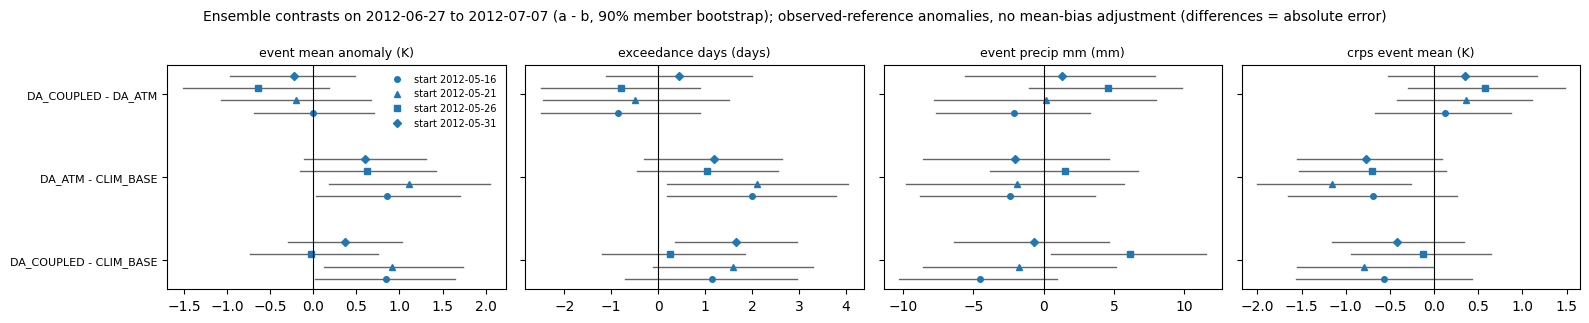

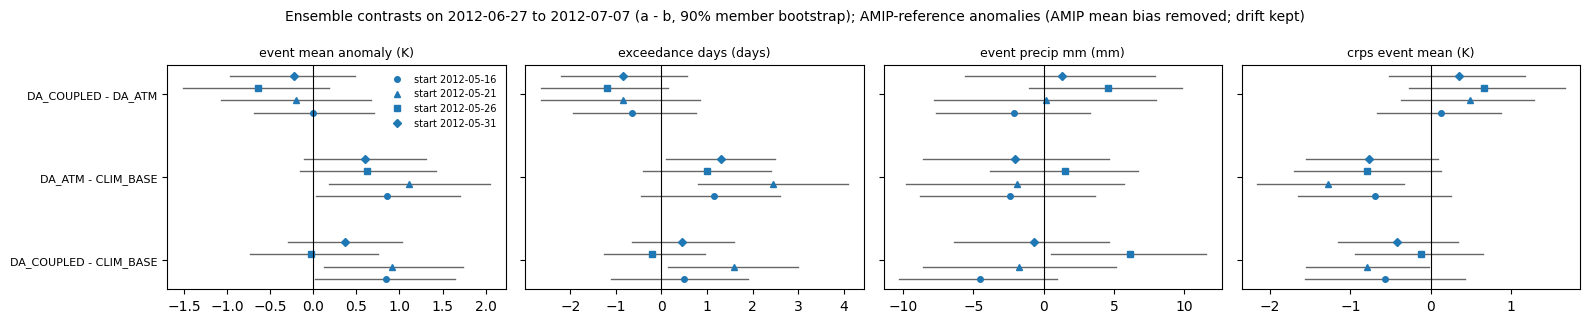

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.heatwave_case import plot_contrasts
from util.heatwave_workflow import METRIC_UNITS, REFERENCE_LABELS

for bias in cfg.biases:
    save(plot_contrasts(contrasts[contrasts.bias == bias], CONTRAST_METRICS, units=METRIC_UNITS,
                        title=f"Ensemble contrasts on {obs.window[0]} to {obs.window[1]} (a - b, 90% member bootstrap); "
                              f"{REFERENCE_LABELS[bias]}"),
         f"heatwave_contrasts_{bias}.png")